# 06 · Weed detector (Colab)

Trains a YOLO detector that boxes `weed`, `moss` and `desired_plant` in a camera frame, so the robot can aim at
each plant (box centre). There are no hand-drawn boxes, so they are made automatically:

1. **Auto-label**: Grounding DINO boxes the plant in every iNaturalist photo; the class comes from the photo's label.
2. **YOLO dataset**: boxes nested inside a bigger box (a leaf or flower of a plant already boxed) are dropped;
   `clean_surface` crops are added as images without objects.
3. **Train** YOLO26n: small and fast, made for CPUs and edge boards.
4. **Test** on photographers never seen in training.

**How to run**

1. Locally: `python tools/pack_detection.py`, then upload `data/processed/detection.zip` to `My Drive/weed-robot/`.
2. Colab: *File → Upload notebook* (this file), *Runtime → Change runtime type → T4 GPU*, *Runtime → Run all*.
3. Everything is saved to `My Drive/weed-robot/`. If the session drops, *Run all* again: labelling and training
   continue where they stopped.
4. Download `My Drive/weed-robot/runs/yolo26n_v1/weights/best.pt` into `models/` of the repo.

Rough times on a T4: auto-labelling ~30 min, training ~1.5–2 h.

Test mAP is measured against the automatic boxes, not hand-drawn ones; for an honest number, correct the test
boxes by hand first.

In [1]:
import csv
import json
import os
import random
import shutil
import subprocess
import sys
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.198", "transformers==5.22.1"],
                   check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/weed-robot")  # detection.zip goes in, results come out
    DATA = Path("/content/detection")                # photos, unzipped to the fast local disk
    YOLO_DIR = Path("/content/yolo")
    if not (DATA / "photos.csv").exists():
        zipfile.ZipFile(OUT / "detection.zip").extractall(DATA.parent)
else:  # local run from notebooks/ in the repo
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    OUT = ROOT / "models" / "detection"
    DATA = ROOT / "data" / "processed" / "detection"
    YOLO_DIR = ROOT / "data" / "processed" / "yolo"
OUT.mkdir(parents=True, exist_ok=True)

import torch
from PIL import Image, ImageDraw

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (on Colab: Runtime -> Change runtime type -> T4 GPU)")

CLASSES = ["weed", "moss", "desired_plant"]  # YOLO class ids 0, 1, 2
with open(DATA / "photos.csv", encoding="utf-8") as f:
    PHOTOS = list(csv.DictReader(f))
print(len(PHOTOS), "images:", dict(Counter(r["label"] for r in PHOTOS)))


def show(image):
    try:
        from IPython.display import display
        display(image)
    except ImportError:
        pass


def grid(tiles, cols=6, size=320):
    sheet = Image.new("RGB", (cols * size, -(-len(tiles) // cols) * size), "black")
    for i, tile in enumerate(tiles):
        sheet.paste(tile, ((i % cols) * size, (i // cols) * size))
    return sheet

Mounted at /content/drive
device: Tesla T4
8283 images: {'moss': 998, 'weed': 4477, 'clean_surface': 521, 'desired_plant': 2287}


## 1. Auto-label with Grounding DINO

One prompt per class; the photo's label decides the class of every box found. Boxes go to `boxes.csv` after
every batch, so an interrupted run continues from there.

In [2]:
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor

DINO = "IDEA-Research/grounding-dino-base"
PROMPTS = {"weed": "plant.", "moss": "moss.", "desired_plant": "plant."}
BOX_THRESHOLD, TEXT_THRESHOLD = 0.3, 0.25
BOXES = OUT / "boxes.csv"  # file, label, score, x1, y1, x2, y2 (0-1); a row without a box = nothing found

done = set()
if BOXES.exists():
    with open(BOXES, encoding="utf-8") as f:
        done = {r["file"] for r in csv.DictReader(f)}
todo = [r for r in PHOTOS if r["label"] in PROMPTS and r["file"] not in done]
print(f"{len(done)} images labelled before, {len(todo)} to go")

if todo:
    processor = AutoProcessor.from_pretrained(DINO)
    dino = AutoModelForZeroShotObjectDetection.from_pretrained(DINO).to(DEVICE).eval()
    new_file = not BOXES.exists()
    with open(BOXES, "a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if new_file:
            w.writerow(["file", "label", "score", "x1", "y1", "x2", "y2"])
        for label, prompt in PROMPTS.items():
            group = [r for r in todo if r["label"] == label]
            for i in range(0, len(group), 4):
                batch = group[i:i + 4]
                images = [Image.open(DATA / "images" / r["file"]).convert("RGB") for r in batch]
                inputs = processor(images=images, text=[prompt] * len(images), return_tensors="pt").to(DEVICE)
                with torch.no_grad():
                    outputs = dino(**inputs)
                results = processor.post_process_grounded_object_detection(
                    outputs, inputs.input_ids, threshold=BOX_THRESHOLD, text_threshold=TEXT_THRESHOLD,
                    target_sizes=[image.size[::-1] for image in images])
                for r, image, res in zip(batch, images, results):
                    W, H = image.size
                    rows = [[r["file"], label, f"{s:.3f}"] + [f"{v:.4f}" for v in (x1 / W, y1 / H, x2 / W, y2 / H)]
                            for s, (x1, y1, x2, y2) in zip(res["scores"].tolist(), res["boxes"].tolist())]
                    w.writerows(rows or [[r["file"], label, "", "", "", "", ""]])
                f.flush()
                if i % 400 == 0:
                    print(f"  {label}: {i + len(batch)}/{len(group)}")
    del dino
    torch.cuda.empty_cache()

7762 images labelled before, 0 to go


## 2. YOLO dataset

Same photographer split as the classifier. Photos where DINO found nothing are left out: an unboxed plant would
teach the model to ignore plants.

In [3]:
def area(b):
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])


def overlap(a, b):
    return area((max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])))


def outer_boxes(boxes, contain=0.8):
    """Biggest first; a box mostly inside a kept one is a leaf or flower of the same plant."""
    kept = []
    for b in sorted(boxes, key=area, reverse=True):
        if area(b) > 0 and all(overlap(b, k) / area(b) < contain for k in kept):
            kept.append(b)
    return kept


found = defaultdict(list)
with open(BOXES, encoding="utf-8") as f:
    for r in csv.DictReader(f):
        if r["score"]:
            found[r["file"]].append(tuple(min(1.0, max(0.0, float(r[k]))) for k in ("x1", "y1", "x2", "y2")))

shutil.rmtree(YOLO_DIR, ignore_errors=True)
counts, skipped = Counter(), Counter()
for r in PHOTOS:
    if r["label"] == "clean_surface":
        boxes = []  # background image: bare pavement has no objects
    else:
        boxes = outer_boxes(found[r["file"]])
        if not boxes:
            skipped[r["label"]] += 1
            continue
    image_dir, label_dir = YOLO_DIR / "images" / r["split"], YOLO_DIR / "labels" / r["split"]
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    try:
        os.link(DATA / "images" / r["file"], image_dir / r["file"])
    except OSError:
        shutil.copy2(DATA / "images" / r["file"], image_dir / r["file"])
    cls = CLASSES.index(r["label"]) if boxes else None
    (label_dir / f"{Path(r['file']).stem}.txt").write_text("".join(
        f"{cls} {(x1 + x2) / 2:.5f} {(y1 + y2) / 2:.5f} {x2 - x1:.5f} {y2 - y1:.5f}\n" for x1, y1, x2, y2 in boxes))
    counts[r["split"], r["label"]] += 1
    counts[r["split"], "boxes"] += len(boxes)

(YOLO_DIR / "data.yaml").write_text(
    f"path: {YOLO_DIR.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    + "".join(f"  {i}: {c}\n" for i, c in enumerate(CLASSES)))
for split in ("train", "val", "test"):
    print(split, {k: v for (s, k), v in counts.items() if s == split})
print("left out, no box found:", dict(skipped))

train {'moss': 790, 'boxes': 8859, 'weed': 3575, 'clean_surface': 436, 'desired_plant': 1825}
val {'moss': 100, 'boxes': 1195, 'weed': 447, 'clean_surface': 44, 'desired_plant': 229}
test {'moss': 99, 'boxes': 1071, 'weed': 448, 'clean_surface': 41, 'desired_plant': 228}
left out, no box found: {'moss': 9, 'weed': 7, 'desired_plant': 5}


Check the boxes on random training images: rows are weed, moss, desired_plant, background
(red = weed, yellow = moss, blue = desired_plant).

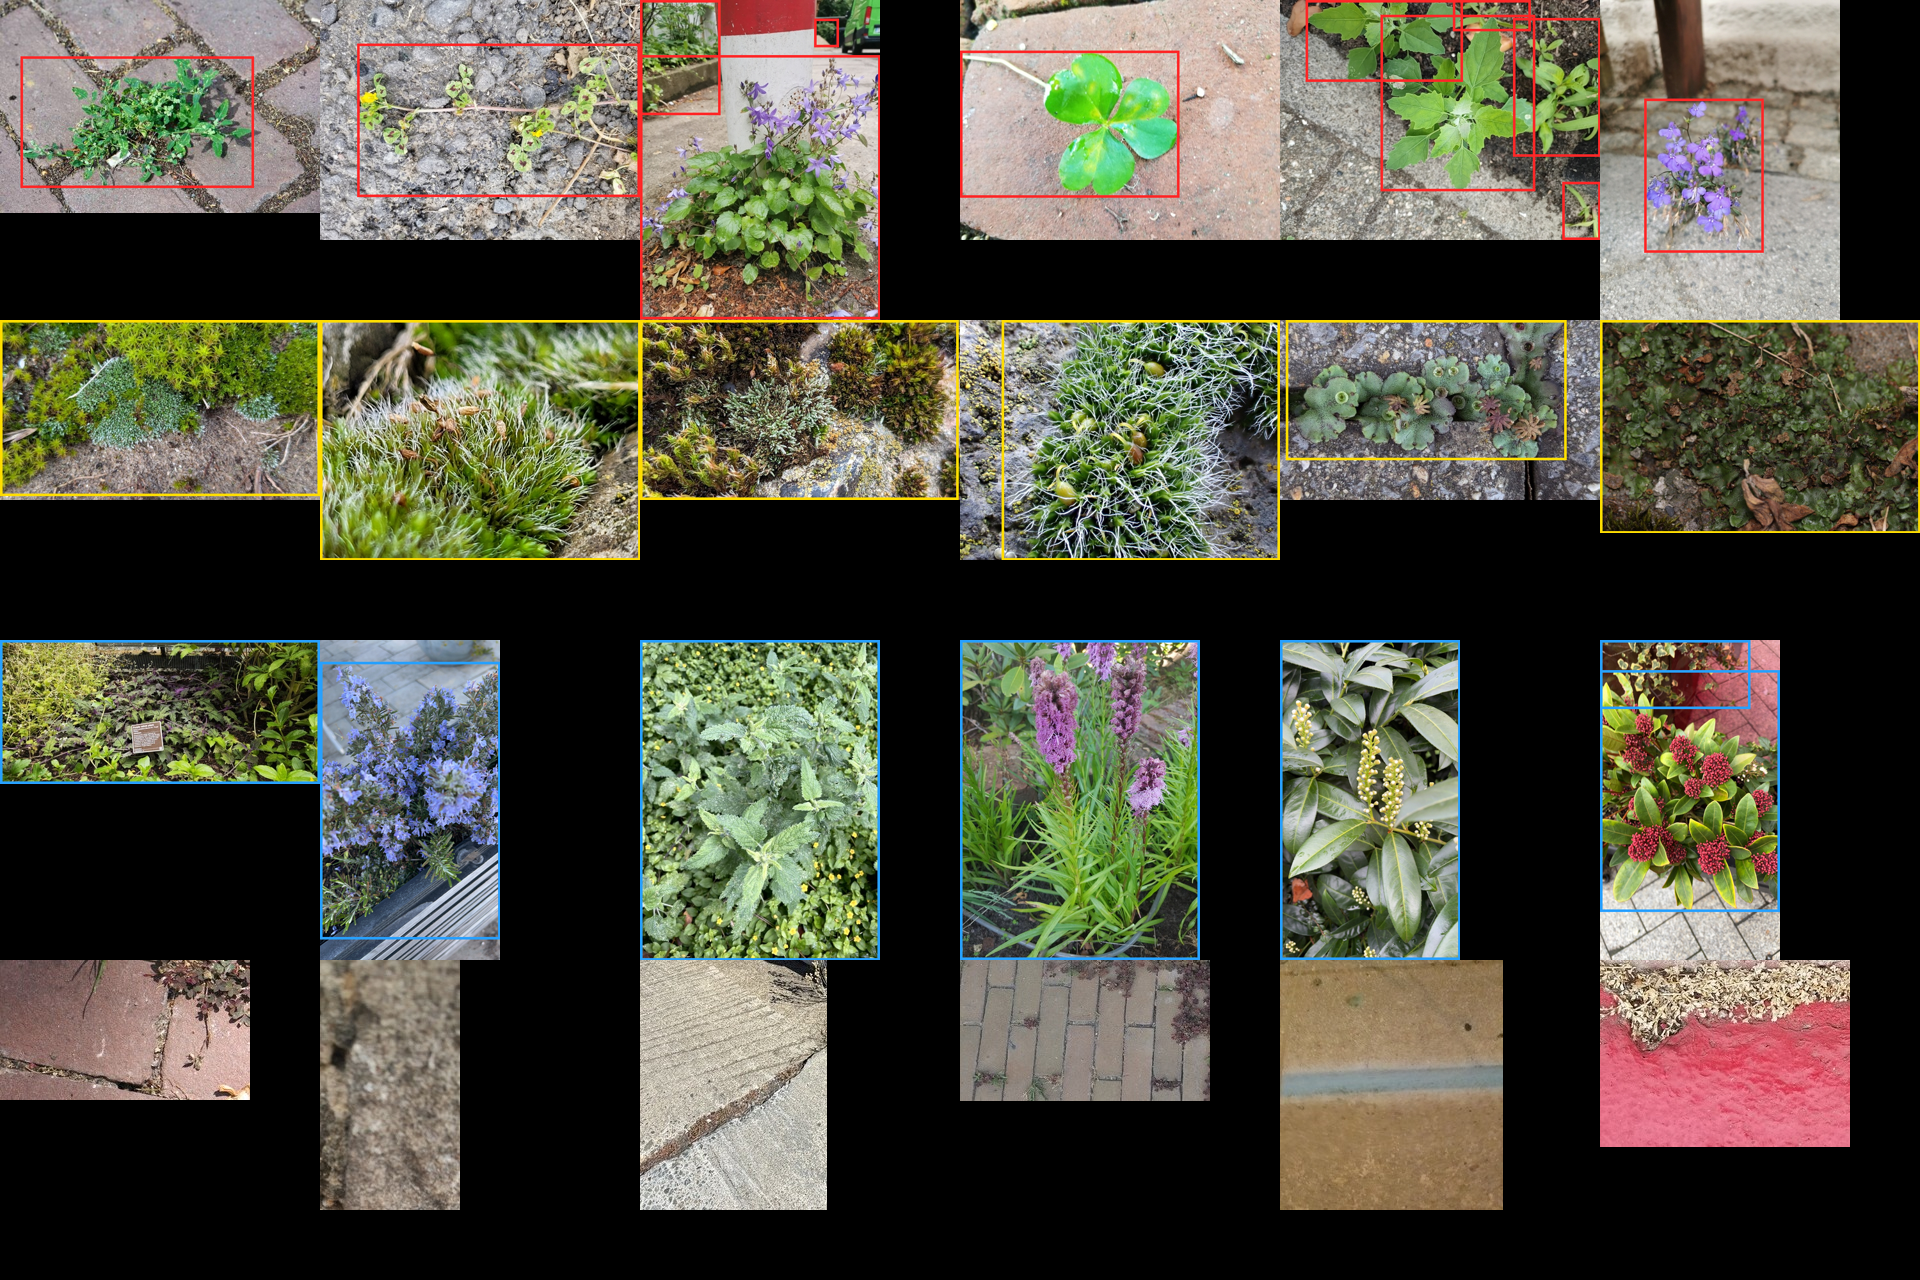

In [4]:
COLORS = [(255, 40, 40), (255, 220, 0), (40, 160, 255)]


def draw_labels(image_path, label_path, size=320):
    image = Image.open(image_path).convert("RGB")
    W, H = image.size
    d = ImageDraw.Draw(image)
    for line in label_path.read_text().splitlines():
        c, cx, cy, w, h = line.split()
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        d.rectangle((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), outline=COLORS[int(c)], width=4)
    image.thumbnail((size, size))
    return image


rng = random.Random(0)
by_class = defaultdict(list)
for p in sorted((YOLO_DIR / "labels" / "train").glob("*.txt")):
    by_class[p.read_text().split(" ", 1)[0]].append(p)  # "" = background image
tiles = [draw_labels(YOLO_DIR / "images" / "train" / f"{p.stem}.jpg", p)
         for key in ("0", "1", "2", "") for p in rng.sample(by_class[key], min(6, len(by_class[key])))]
preview = grid(tiles)
preview.save(OUT / "preview_labels.jpg")
show(preview)

## 3. Train YOLO26n

The camera looks straight down, so up/down flips are valid. Mosaic and scale make plants smaller, closer to their
size in a robot frame. Weights are saved to Drive every epoch; running this cell again resumes the run.

In [5]:
from ultralytics import YOLO

RUN_NAME, EPOCHS = "yolo26n_v1", 60
RUNS = OUT / "runs"
last = RUNS / RUN_NAME / "weights" / "last.pt"
if last.exists() and torch.load(last, map_location="cpu", weights_only=False)["optimizer"] is None:
    # A finished run keeps no optimizer; resuming it would silently start an unrelated new training
    print(f"{RUN_NAME} has finished; change RUN_NAME to train again")
elif last.exists():
    YOLO(last).train(resume=True)
else:
    YOLO("yolo26n.pt").train(
        data=str(YOLO_DIR / "data.yaml"), epochs=EPOCHS, imgsz=512, batch=32, patience=15, workers=2,
        cache="ram" if IN_COLAB else False, project=str(RUNS), name=RUN_NAME, exist_ok=True, seed=0,
        flipud=0.5, fliplr=0.5, scale=0.6, close_mosaic=10)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
yolo26n_v1 has finished; change RUN_NAME to train again


## 4. Test

Photographers in the test split were never seen in training. The reference boxes are DINO's, so this is agreement
with the auto-labels, not with a human.

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1975.4±683.0 MB/s, size: 133.9 KB)
val: Scanning /content/yolo/labels/test... 816 images, 41 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 816/816 1.5Kit/s 0.5s
val: New cache created: /content/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 1.9it/s 13.9s
                   all        816       1071      0.826      0.744      0.837      0.726
                  weed        448        680      0.811      0.731      0.832      0.697
                  moss         99        116      0.861      0.733      0.836      0.719
         desired_plant        228        275      0.808      0.767      0.842      0.762
Speed: 1.8ms preprocess, 4.0ms inference, 0.0ms loss, 3.0ms postprocess per image
Resu

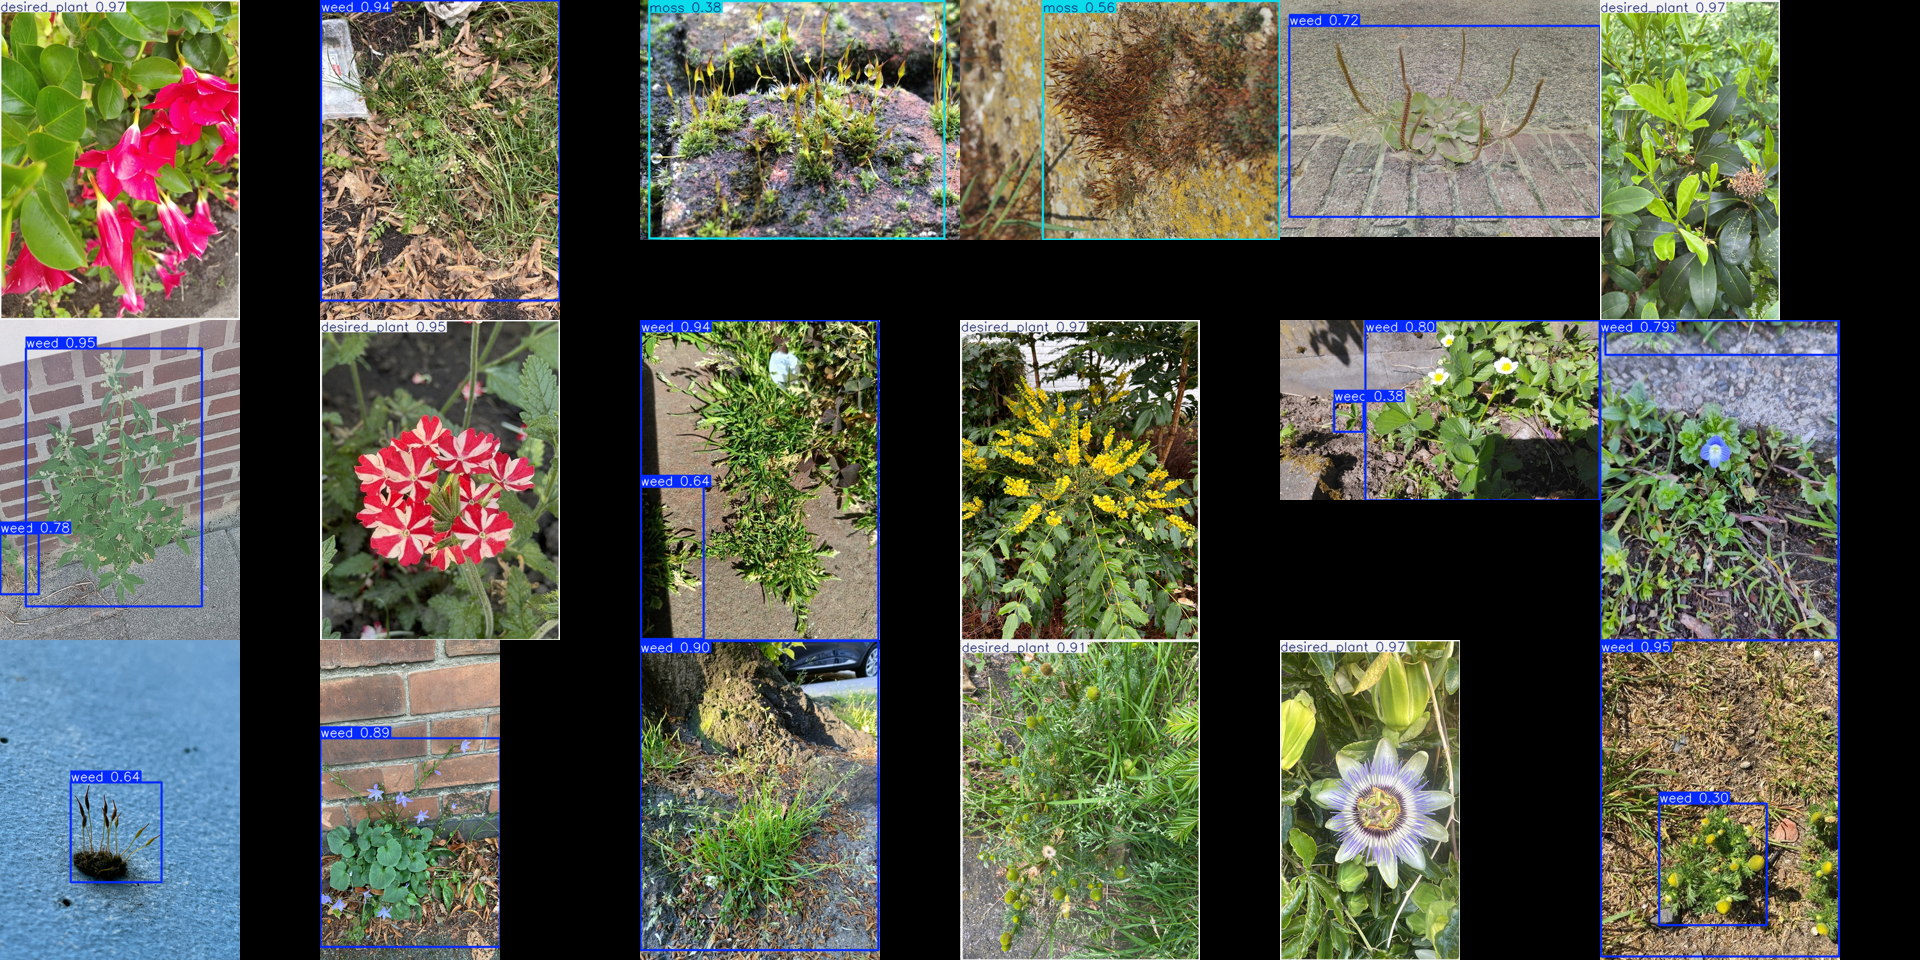

now download /content/drive/MyDrive/weed-robot/runs/yolo26n_v1/weights/best.pt into models/ of the repo


In [6]:
best = YOLO(RUNS / RUN_NAME / "weights" / "best.pt")
m = best.val(data=str(YOLO_DIR / "data.yaml"), split="test", imgsz=512, batch=32,
             project=str(RUNS), name=f"{RUN_NAME}_test", exist_ok=True)
result = {"mAP50": m.box.map50, "mAP50-95": m.box.map, "classes": {}}
print(f"TEST  mAP50 {m.box.map50:.3f}  mAP50-95 {m.box.map:.3f}")
for i, c in enumerate(m.box.ap_class_index):
    result["classes"][CLASSES[c]] = {"precision": m.box.p[i], "recall": m.box.r[i], "mAP50": m.box.ap50[i]}
    print(f"  {CLASSES[c]:14s} precision {m.box.p[i]:.3f}  recall {m.box.r[i]:.3f}  mAP50 {m.box.ap50[i]:.3f}")
(RUNS / RUN_NAME / "test_metrics.json").write_text(json.dumps(result, indent=2, default=float))

test_images = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))
tiles = []
for res in best.predict([str(p) for p in rng.sample(test_images, min(18, len(test_images)))],
                        imgsz=512, conf=0.25, verbose=False):
    tile = Image.fromarray(res.plot()[..., ::-1])
    tile.thumbnail((320, 320))
    tiles.append(tile)
predictions = grid(tiles)
predictions.save(RUNS / RUN_NAME / "test_predictions.jpg")
show(predictions)
print("now download", RUNS / RUN_NAME / "weights" / "best.pt", "into models/ of the repo")

## Using the detector on the robot

```python
from ultralytics import YOLO

model = YOLO("models/yolo26n_weeds.pt")
for box in model("frame.jpg", conf=0.25)[0].boxes:
    x, y = box.xywh[0][:2].tolist()  # aim point in pixels
    print(model.names[int(box.cls)], round(float(box.conf), 2), x, y)
```